In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def get_run_names(str_list):
    run_names = []
    for i,string in enumerate(str_list):
        run_names.append(string.split("_")[0]+'_'+string.split("_")[1])
    return run_names

In [3]:
def normalize(DA):
    start_date = '2030-06-30T12:00:00.000000000'
    end_date = '2090-06-30T12:00:00.000000000'
    normalized_DA = DA/DA.loc[start_date:end_date].mean('time')
    return normalized_DA

In [4]:
'''
Importing the datasets
'''
import os
# Path to the dataset directory
dataset_path = "/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays/ssp370/"

%cd /emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays/ssp370/

# List all files, excluding those with 'unfilt' in the name
dataset_file_list_all = [
    f for f in os.listdir(dataset_path) 
    if os.path.isfile(os.path.join(dataset_path, f)) and 'GHA' in f and 'all' in f# and 'CanESM' in f 
]

dataset_file_list_all = sorted(dataset_file_list_all)

# List all files, excluding those with 'unfilt' in the name
dataset_file_list_retrograding = [
    f for f in os.listdir(dataset_path) 
    if os.path.isfile(os.path.join(dataset_path, f)) and 'GHA' in f and 'retrograding' in f# and 'CanESM' in f 
]

dataset_file_list_retrograding = sorted(dataset_file_list_retrograding)

# List all files, excluding those with 'unfilt' in the name
dataset_file_list_upstream = [
    f for f in os.listdir(dataset_path) 
    if os.path.isfile(os.path.join(dataset_path, f)) and 'GHA' in f and 'upstream' in f# and 'CanESM' in f 
]

dataset_file_list_upstream = sorted(dataset_file_list_upstream)

/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays/ssp370


In [5]:
#import data
dss_all = []
for name in dataset_file_list_all:
    dss_all.append(xr.open_dataset(name))
#import data
dss_retrograding = []
for name in dataset_file_list_retrograding:
    dss_retrograding.append(xr.open_dataset(name))
#import data
dss_upstream = []
for name in dataset_file_list_upstream:
    dss_upstream.append(xr.open_dataset(name))

In [6]:
print(len(dss_all))

51


In [7]:
#compute ensemble average
combined_all = xr.concat(dss_all, dim='ensemble')
average_all = combined_all.mean(dim='ensemble')
combined_retrograding = xr.concat(dss_retrograding, dim='ensemble')
average_retrograding = combined_retrograding.mean(dim='ensemble')
combined_upstream = xr.concat(dss_upstream, dim='ensemble')
average_upstream = combined_upstream.mean(dim='ensemble')

In [8]:
#compute linear regrassion
from scipy.stats import linregress
x=np.arange(0,len(average_all['GHA monthly blocking frequency']),1)

#all
result = linregress(x,average_all['GHA monthly blocking frequency'])
y_all = result.intercept + result.slope*x
slope_all = result.slope * 3*10 #convert to %/per_decade
slope_stderr_all = result.stderr * 3*10

#retrograding
result = linregress(x,average_retrograding['GHA monthly blocking frequency'])
y_retrograding = result.intercept + result.slope*x
slope_retrograding = result.slope * 3*10
slope_stderr_retrograding = result.stderr * 3*10

#upstream
result = linregress(x,average_upstream['GHA monthly blocking frequency'])
y_upstream = result.intercept + result.slope*x
slope_upstream = result.slope * 3*10
slope_stderr_upstream = result.stderr * 3*10

(0.0, 0.16)

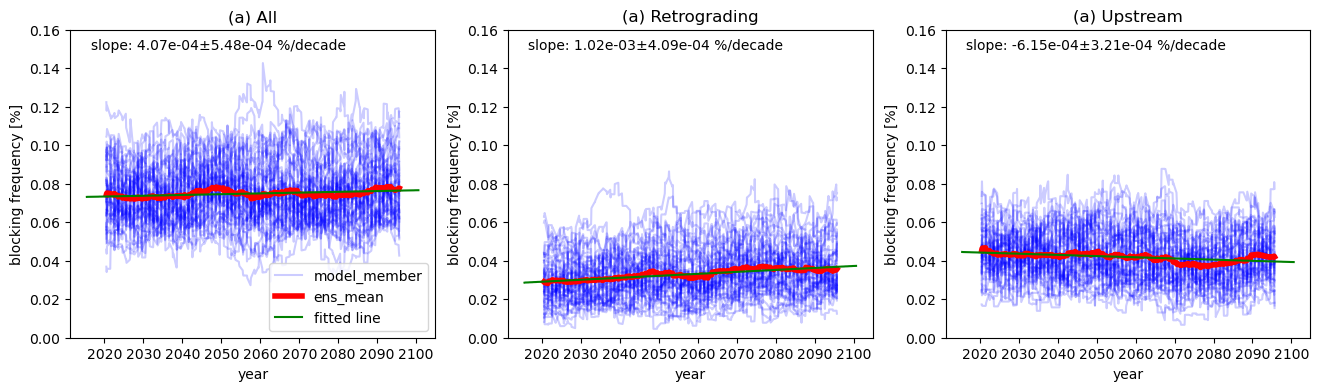

In [9]:
labels = ['all','retrograding (WBI > 0)','upstream (WBI < 0)']
widths = [2,0.6,0.6]

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))
#plt.suptitle('Monthly summer blocking frequency (JJA) given as fraction of blocked days')

axes[0].set_title('(a) All')
for i,element in enumerate(dss_all):
    if i == 0:
        axes[0].plot(element['time'],(element['GHA monthly blocking frequency']).rolling(time=3*10,center=True).mean('time'),color='blue',alpha=0.2,label='model_member')
    else:
        axes[0].plot(element['time'],(element['GHA monthly blocking frequency']).rolling(time=3*10,center=True).mean('time'),color='blue',alpha=0.2)
axes[0].plot(average_all['time'],(average_all['GHA monthly blocking frequency']).rolling(time=3*10,center=True).mean('time'),color = 'Red',label='ens_mean',linewidth=4.0)
axes[0].plot(average_all['time'],y_all, 'g', label='fitted line')
axes[0].text(average_all['time'][3], 0.15, 'slope: ' + f"{slope_all:.2e}" + "±" + f"{slope_stderr_all:.2e}" + " %/decade")
axes[0].set_ylabel('blocking frequency [%]')
axes[0].set_xlabel('year')
axes[0].legend(loc='best', bbox_to_anchor=(0.5, 0., 0.5, 0.5))
axes[0].set_ylim(0,0.16)

axes[1].set_title('(a) Retrograding')
for element in dss_retrograding:
    axes[1].plot(element['time'],(element['GHA monthly blocking frequency']).rolling(time=3*10,center=True).mean('time'),color='blue',alpha=0.2)
axes[1].plot(average_retrograding['time'],(average_retrograding['GHA monthly blocking frequency']).rolling(time=3*10,center=True).mean('time'),color = 'Red',linewidth=4.0)
axes[1].plot(average_retrograding['time'],y_retrograding, 'g', label='fitted line')
axes[1].text(average_retrograding['time'][3], 0.15, 'slope: ' + f"{slope_retrograding:.2e}" + "±" + f"{slope_stderr_retrograding:.2e}"+ " %/decade")
axes[1].set_ylabel('blocking frequency [%]')
axes[1].set_xlabel('year')
axes[1].set_ylim(0,0.16)

axes[2].set_title('(a) Upstream')
for element in dss_upstream:
    axes[2].plot(element['time'],(element['GHA monthly blocking frequency']).rolling(time=3*10,center=True).mean('time'),color='blue',alpha=0.2)
axes[2].plot(average_upstream['time'],(average_upstream['GHA monthly blocking frequency']).rolling(time=3*10,center=True).mean('time'),color = 'Red',linewidth=4.0)
axes[2].plot(average_upstream['time'],y_upstream, 'g', label='fitted line')
axes[2].text(average_upstream['time'][3], 0.15, 'slope: ' + f"{slope_upstream:.2e}" + "±" + f"{slope_stderr_upstream:.2e}"+ " %/decade")
axes[2].set_ylabel('blocking frequency [%]')
axes[2].set_xlabel('year')
axes[2].set_ylim(0,0.16)


(0.0, 2.5)

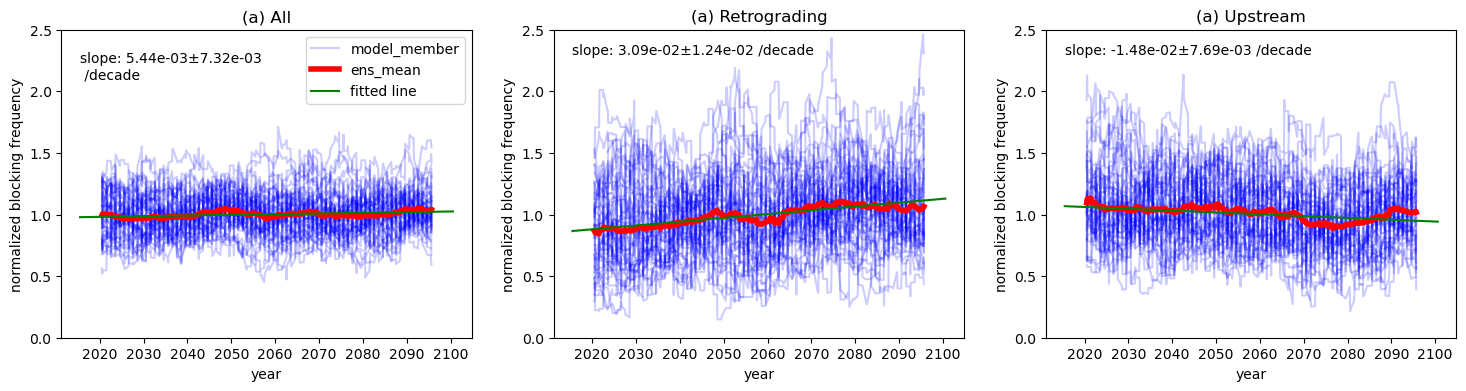

In [10]:
labels = ['all','retrograding (WBI > 0)','upstream (WBI < 0)']
widths = [2,0.6,0.6]

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 4))
#plt.suptitle('Monthly summer blocking frequency (JJA) given as fraction of blocked days')

axes[0].set_title('(a) All')
for i,element in enumerate(dss_all):
    if i == 0:
        axes[0].plot(element['time'],(normalize(element['GHA monthly blocking frequency'])).rolling(time=3*10,center=True).mean('time'),color='blue',alpha=0.2,label='model_member')
    else:
        axes[0].plot(element['time'],(normalize(element['GHA monthly blocking frequency'])).rolling(time=3*10,center=True).mean('time'),color='blue',alpha=0.2)
mean = (average_all['GHA monthly blocking frequency']).rolling(time=3*10,center=True).mean('time').mean().values
axes[0].plot(average_all['time'],normalize((average_all['GHA monthly blocking frequency']).rolling(time=3*10,center=True).mean('time')),color = 'Red',label='ens_mean',linewidth=4.0)
axes[0].plot(average_all['time'],y_all/mean, 'g', label='fitted line')
axes[0].text(average_all['time'][0], 2.1, 'slope: ' + f"{slope_all/mean:.2e}" + "±" + f"{slope_stderr_all/mean:.2e}" + "\n /decade")
axes[0].set_ylabel('normalized blocking frequency')
axes[0].set_xlabel('year')
axes[0].legend(loc='upper right')
axes[0].set_ylim(0,+2.5)

axes[1].set_title('(a) Retrograding')
for element in dss_retrograding:
    axes[1].plot(element['time'],(normalize(element['GHA monthly blocking frequency'])).rolling(time=3*10,center=True).mean('time'),color='blue',alpha=0.2)
mean = (average_retrograding['GHA monthly blocking frequency']).rolling(time=3*10,center=True).mean('time').mean().values
axes[1].plot(average_retrograding['time'],normalize((average_retrograding['GHA monthly blocking frequency']).rolling(time=3*10,center=True).mean('time')),color = 'Red',linewidth=4.0)
axes[1].plot(average_retrograding['time'],y_retrograding/mean, 'g', label='fitted line')
axes[1].text(average_retrograding['time'][0], 2.3, 'slope: ' + f"{slope_retrograding/mean:.2e}" + "±" + f"{slope_stderr_retrograding/mean:.2e}"+ " /decade")
axes[1].set_ylabel('normalized blocking frequency')
axes[1].set_xlabel('year')
axes[1].set_ylim(0,+2.5)

axes[2].set_title('(a) Upstream')
for element in dss_upstream:
    axes[2].plot(element['time'],(normalize(element['GHA monthly blocking frequency'])).rolling(time=3*10,center=True).mean('time'),color='blue',alpha=0.2)
mean = (average_upstream['GHA monthly blocking frequency']).rolling(time=3*10,center=True).mean('time').mean().values
axes[2].plot(average_upstream['time'],normalize((average_upstream['GHA monthly blocking frequency']).rolling(time=3*10,center=True).mean('time')),color = 'Red',linewidth=4.0)
axes[2].plot(average_upstream['time'],y_upstream/mean, 'g', label='fitted line')
axes[2].text(average_upstream['time'][0], 2.3, 'slope: ' + f"{slope_upstream/mean:.2e}" + "±" + f"{slope_stderr_upstream/mean:.2e}"+ " /decade")
axes[2].set_ylabel('normalized blocking frequency')
axes[2].set_xlabel('year')
axes[2].set_ylim(0,+2.5)
